In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## EDA

In [2]:
#MTS Library
df = pd.read_csv('..\\data\\raw\\interactions.csv')

In [3]:
df

,user_id,item_id,progress,rating,start_date
0,126706,14433,80,NaN,2018-01-01
1,127290,140952,58,NaN,2018-01-01
2,66991,198453,89,NaN,2018-01-01
3,46791,83486,23,5.0,2018-01-01
4,79313,188770,88,5.0,2018-01-01
...,...,...,...,...,...
1533073,76968,285394,95,NaN,2019-12-31
1533074,153877,285394,76,5.0,2019-12-31
1533075,90021,73789,97,NaN,2019-12-31
1533076,6452,77993,39,NaN,2019-12-31


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1533078 entries, 0 to 1533077
Data columns (total 5 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   user_id     1533078 non-null  int64  
 1   item_id     1533078 non-null  int64  
 2   progress    1533078 non-null  int64  
 3   rating      285356 non-null   float64
 4   start_date  1533078 non-null  str    
dtypes: float64(1), int64(3), str(1)
memory usage: 58.5 MB


<Axes: xlabel='progress', ylabel='count'>

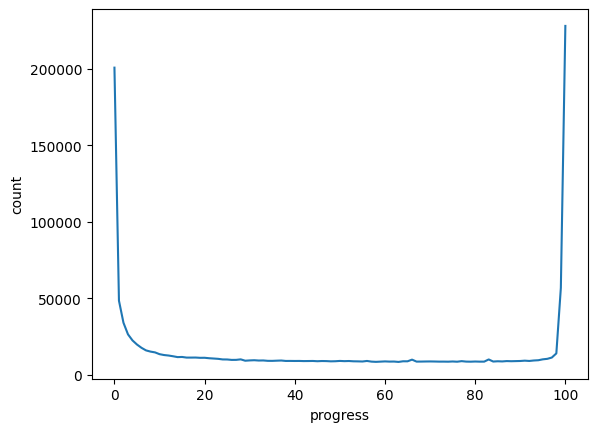

In [5]:
sns.lineplot(df['progress'].value_counts())

<Axes: xlabel='rating', ylabel='Count'>

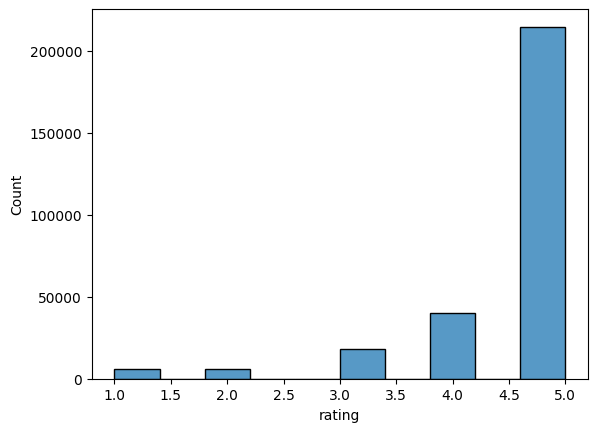

In [6]:
sns.histplot(df['rating'], bins = 10)

In [7]:
df['start_date'] = pd.to_datetime(df['start_date'])

In [8]:
df_implicit = df.copy()
df_explicit = df.dropna()

<Axes: xlabel='user_id', ylabel='Count'>

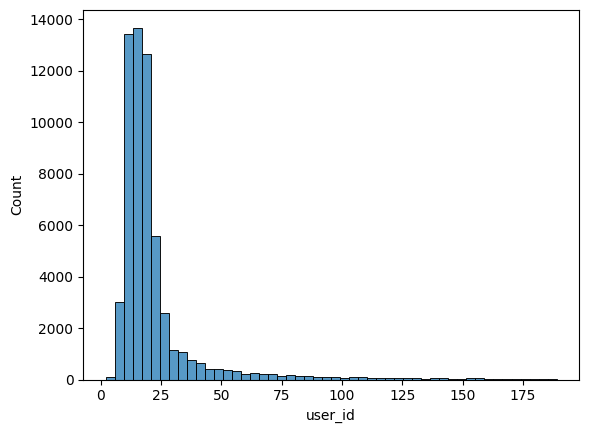

In [9]:
book_readers = df_implicit.groupby('item_id')['user_id'].count()
sns.histplot(book_readers[book_readers < book_readers.quantile(0.99)], bins=50)

<Axes: xlabel='item_id', ylabel='Count'>

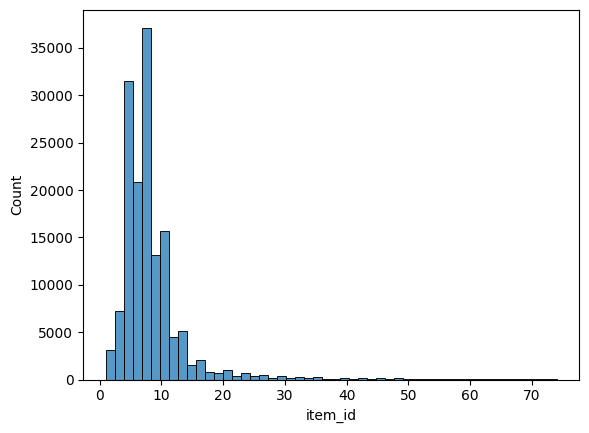

In [10]:
user_books = df_implicit.groupby('user_id')['item_id'].count()
sns.histplot(user_books[user_books < user_books.quantile(0.99)], bins=50)

In [11]:
def filter_positive_interactions(data:pd.DataFrame):
    
    rating = pd.to_numeric(data['rating'], errors='coerce')
    progress = pd.to_numeric(data['progress'], errors='coerce')

    mask = (rating >= 4.0) | (progress >= 80)

    return data[mask]

In [12]:
df_implicit_positive = filter_positive_interactions(df_implicit)

In [13]:
def filter_data(data: pd.DataFrame, min_book_readers=20, min_user_books=10):
    
    while True:
        old_len = data.shape[0]

        book_readers = data.groupby('item_id')['user_id'].count()
        valid_books = book_readers[book_readers >= min_book_readers].index
        data = data[data['item_id'].isin(valid_books)]

        user_books = data.groupby('user_id')['item_id'].count()
        valid_users = user_books[user_books >= min_user_books].index
        data = data[data['user_id'].isin(valid_users)]
        
        if old_len == data.shape[0]:
            break

    return data

In [14]:
df_implicit_positive = filter_data(df_implicit_positive)

In [15]:
df_implicit_positive

,user_id,item_id,progress,rating,start_date
29,137220,167814,99,NaN,2018-01-01
57,105213,249337,100,NaN,2018-01-01
92,46125,308861,100,4.0,2018-01-01
168,24438,185522,100,5.0,2018-01-01
196,125423,258438,99,5.0,2018-01-01
...,...,...,...,...,...
1532974,83403,97109,100,3.0,2019-12-31
1532976,74716,131294,99,5.0,2019-12-31
1533030,89522,32456,100,NaN,2019-12-31
1533058,80070,157666,100,3.0,2019-12-31


In [16]:
df_implicit_positive.info()

<class 'pandas.DataFrame'>
Index: 129762 entries, 29 to 1533061
Data columns (total 5 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     129762 non-null  int64         
 1   item_id     129762 non-null  int64         
 2   progress    129762 non-null  int64         
 3   rating      63617 non-null   float64       
 4   start_date  129762 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(3)
memory usage: 5.9 MB


In [17]:
def split_by_time(data:pd.DataFrame, test_size=0.2):

    data['start_date'] = pd.to_datetime(data['start_date'])

    # сначала группируем по пользователям, зачтем внутри группы по времени
    data = data.sort_values(['user_id', 'start_date']).reset_index(drop=True)
    
    ordered_readings = data.groupby('user_id').cumcount()

    group_size = data.groupby('user_id')['user_id'].transform('size')

    train_end = (group_size * (1 - test_size)).astype(int)

    mask = ordered_readings < train_end

    train = data[mask]
    test = data[~mask]

    return train, test

In [18]:
train, test = split_by_time(df_implicit_positive)
train, val = split_by_time(train, test_size=0.1)

In [19]:
train

,user_id,item_id,progress,rating,start_date
0,21,227272,100,NaN,2018-12-05
1,21,72618,100,NaN,2019-03-30
2,21,72356,100,NaN,2019-07-23
3,21,212027,99,NaN,2019-07-24
4,21,121640,100,5.0,2019-07-29
...,...,...,...,...,...
102408,159610,300766,97,NaN,2018-05-20
102409,159610,24677,98,NaN,2018-05-22
102410,159610,321015,96,NaN,2018-05-27
102411,159610,126070,100,NaN,2018-05-30


# CF

## User to User

Для реализации колоборативной фильтрации необходимо построить матрицу пользователь x книга.

За положительное взаимодействие будем считать что пользователь оставил хороший отзыв о книге или прочёл больше половины 

Также важно отметить, что мы не можем утверждать, что пользователям, провитавшим книгу на 10%, она не понравилась. Может они купили её или взяли прочитать в библиотеке. Но другого выхода нет, поскульку у нас нет возможности собрать всю информацию о пользователях 

In [20]:
from scipy.sparse import csr_matrix
from sklearn.base import BaseEstimator
from sklearn.neighbors import NearestNeighbors

In [21]:
class User2UserCF(BaseEstimator):

    def __init__(self, n_neighbors=30, user_col='user_id', item_col='item_id'):
        self.user_col = user_col
        self.item_col = item_col
        self.n_neighbors = n_neighbors

    def fit(self, X:pd.DataFrame, y=None):
        """Создаём матрицу взаимодействия пользователь х книга"""
        # Какие у нас есть пары уникальных взаимодействий
        interactions = X[[self.user_col, self.item_col]].dropna().drop_duplicates()
        
        # Задаёт обратное соотвествие 
        self.user_ids_ = interactions[self.user_col].unique()
        self.item_ids_ = interactions[self.item_col].unique()

        # Задаём сжатие индексов (прямое соотаветствие)
        self.user2idx = {user_id:idx for idx, user_id in enumerate(self.user_ids_)}
        self.item2idx = {item_id:idx for idx, item_id in enumerate(self.item_ids_)}

        # Переводим пары взаимодействия пользователь-объект в новые индексы
        rows = interactions[self.user_col].map(self.user2idx)
        cols = interactions[self.item_col].map(self.item2idx)

        self.matrix_ = csr_matrix(
            (np.ones(len(interactions)), (rows, cols)),
            shape=(len(self.user_ids_), len(self.item_ids_))
        )

        self.nn_ = NearestNeighbors(
            metric='cosine',
            algorithm='brute'
        )
        self.nn_.fit(self.matrix_)

        # Находим соседей сразу для всех пользователей (оптимизация)
        n_users = self.matrix_.shape[0]
        k = min(self.n_neighbors, n_users - 1)

        self.neighbor_distances_, self.neighbor_indexes_ = self.nn_.kneighbors(X=None, n_neighbors=k)

        return self
    
    def _get_neighbors(self, user_id):
        """Возвращает индексы соседей и их сходство с пользователем."""

        if user_id not in self.user_ids_:
            raise ValueError("Нет информации о пользователе")
        
        user_idx = self.user2idx[user_id]
        
        distances = self.neighbor_distances_[user_idx]
        indexes = self.neighbor_indexes_[user_idx]

        similarities = 1 - distances

        # Убираем нулевые сходства
        mask = similarities > 0

        return indexes[mask], similarities[mask]

    def similar_users(self, user_id):
        """Возвращает наиболее похожих пользователей."""
        indices, similarities = self._get_neighbors(user_id)

        return pd.DataFrame({
            self.user_col: self.user_ids_[indices],
            'similarity': similarities
        })
    
    def recommend(self, user_id, n_recommendations=10):
        """Рекомендует книги по взвешенным голосам соседей."""

        columns = [self.item_col, 'score']

        neighbor_indixes, similarities = self._get_neighbors(user_id)

        if len(neighbor_indixes) == 0:
            return pd.DataFrame(columns=columns)
        
        user_idx = self.user2idx[user_id]
        
        # Взвешиваем взаимодействия соседей по их сходству
        scores = (self.matrix_[neighbor_indixes].T @ similarities).ravel()

        # Не рекоммендуем книги, которые пользователь уже читал 
        seen = self.matrix_[user_idx].indices
        scores[seen] = -1

        # Получаем индексы книг, которые можно реккомендовать 
        candidates = np.flatnonzero(scores > 0)

        if len(candidates) == 0:
            return pd.DataFrame(columns=columns)

        # Сортируем книги по убыванию score
        order = np.argsort(scores[candidates])[::-1]
        top_indices = candidates[order[:n_recommendations]]

        return pd.DataFrame({
            self.item_col: self.item_ids_[top_indices],
            'score': scores[top_indices]
        })

In [22]:
CF = User2UserCF()

In [23]:
CF.fit(df_implicit_positive)

,n_neighbors,30
,user_col,'user_id'
,item_col,'item_id'


In [24]:
user = 137220
ans = CF.recommend(user)

In [25]:
ans

,item_id,score
0,148773,2.811720
1,61522,2.577588
2,180275,2.461013
3,2519,2.232348
4,110009,2.232348
5,196238,2.057535
6,28502,1.982028
7,159455,1.982028
8,148399,1.982028
9,156823,1.744203


## Оценка качества моделей

**Precision@K** - какая доля рекомендованных книг оказалась релевантной?

**Recall@K** - какую долю всех релевантных книг мы нашли в топ-K?

По качеству порядка релевантных книг:

**Average Precision (AP@K)** оценивает Precision в тех позициях списка, где встретилась релевантная книга.

**MAP@K** — среднее значение AP@K по всем оцениваемым пользователям:

**NDCG@K** - главное чтобы в начале списка стояли более релевантные книги

In [ ]:
def evaluate_user2user(model, train:pd.DataFrame, test:pd.DataFrame, k=10):

    user_col = model.user_col
    item_col = model.item_col

    # Уникальные пары пользователь книга
    train_pairs = train[[user_col, item_col]].dropna().drop_duplicates().assign(_seen=True)
    test_pairs = test[[user_col, item_col]].dropna().drop_duplicates()

    # Исключаем книги, которые уже встретились в train 
    test_pairs = test_pairs.merge(train_pairs, how='left', on=[user_col, item_col])
    test_pairs = test_pairs[test_pairs['_seen'].isna()][[user_col, item_col]]

    # Релевантные книги для каждого пользователя 
    relevant_by_user = test_pairs.groupby(user_col)[item_col].apply(set).to_dict()

    results = []

    for user_id, relevant_items in relevant_by_user.items():

        recommended = model.recommend(user_id, k)[item_col].tolist()

        # Релевантность каждой книги в порядке выдачи: 0 или 1
        rel = np.array(
            [int(item in relevant_items) for item in recommended]
        )

        hits = np.sum(rel)
        ranks = np.arange(1, len(rel) + 1)

        # Precision@k
        precision_k = hits / k 

        # Recall@k
        recall_k = hits / len(relevant_items) 
        
        # DCG@k
        dcg = np.sum(rel / np.log2(ranks + 1))

        # IDCG@K: идеальное ранжирование
        ideal_len = min(len(relevant_items), k)
        ideal_ranks = np.arange(1, ideal_len + 1)

        idcg = np.sum(1 / np.log2(ideal_ranks + 1))

        # NDCG@K
        ndcg = dcg / idcg 

        # AP@K
        if len(rel) > 0:
            precision_at_rank = np.cumsum(rel) / ranks

            ap = np.sum(precision_at_rank * rel) / min(len(relevant_items), k)
        else:
            ap = 0.0

        results.append({
            'user_id': user_id,
            f'Precision@{k}': precision_k,
            f'Recall@{k}': recall_k,
            f'NDCG@{k}': ndcg,
            f'MAP@{k}': ap
        })

    per_user = pd.DataFrame(results)

    # Усредняем метрики по пользователям
    metrics = per_user.drop(columns='user_id').mean()

    return metrics, per_user

In [27]:
CF = User2UserCF(n_neighbors=30)
CF.fit(train)

metrics, per_user = evaluate_user2user(model=CF, train=train, test=test, k=10)

print(metrics)

Precision@10    0.063908
Recall@10       0.135018
NDCG@10         0.108880
MAP@10          0.062544
dtype: float64


In [28]:
neighbor_values = [10, 20, 30, 50, 100]

results = []

for n in neighbor_values:
    model = User2UserCF(n_neighbors=n)
    model.fit(train)

    metrics, _ = evaluate_user2user(
        model=model,
        train=train,
        test=val,
        k=10
    )

    results.append({
        'n_neighbors': n,
        **metrics.to_dict()
    })

comparison = pd.DataFrame(results).sort_values(
    'NDCG@10',
    ascending=False
)

comparison

,n_neighbors,Precision@10,Recall@10,NDCG@10,MAP@10
4,100,0.053982,0.246149,0.166297,0.117776
3,50,0.053129,0.241060,0.166197,0.119621
2,30,0.053043,0.241716,0.164164,0.117473
1,20,0.051251,0.232497,0.159251,0.113984
0,10,0.047042,0.215382,0.149459,0.107539


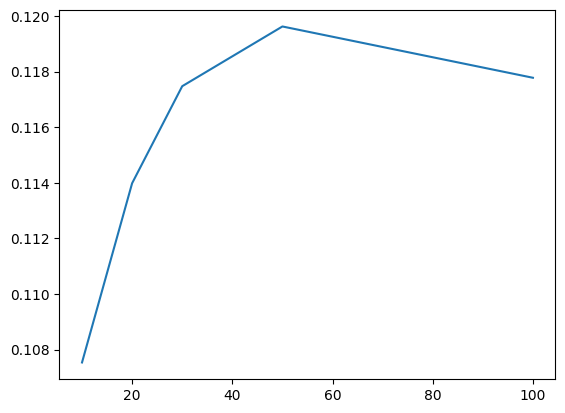

In [30]:
plt.plot(comparison['n_neighbors'], comparison['MAP@10'])

In [31]:
CF = User2UserCF(n_neighbors=50)
CF.fit(train)

metrics, per_user = evaluate_user2user(model=CF, train=train, test=test, k=10)

print(metrics)

Precision@10    0.065501
Recall@10       0.140123
NDCG@10         0.112471
MAP@10          0.064721
dtype: float64


## Implicit ALS

**ALS (Alternating Least Squares)** — это также алгоритм коллаборативной фильтрации, но его идея заключается в том, чтобы представить пользователей и книги в виде латентых векторов небольшой размерности и научиться подбирать эти векторы так, чтобы они отражали предпочтения пользователей, а векторы книг - их характеристики.
**Implicit ALS** может работать также с неявным фидбеком. Вместо использования только положительных взаимодействий, будем использовать все доступные.

In [ ]:
from scipy.sparse import csr_matrix

In [ ]:
def make_matrix(data:pd.DataFrame, user_col='user_id', item_col='item_id', progress_col='progress', rating_col='rating', user2idx=None, item2idx=None, use_weights=True):

    interactions = data[[user_col, item_col, progress_col, rating_col]].dropna(subset=[user_col, item_col])

    interactions[progress_col] = pd.to_numeric(interactions[progress_col], errors="coerce").clip(0, 100)
    interactions[rating_col] = pd.to_numeric(interactions[rating_col], errors="coerce").clip(1, 5)

    # Если одна пара встретилась несколько раз, берём максимальный прогресс и среднюю оценку
    interactions = interactions.groupby([user_col, item_col], as_index=False).agg({progress_col : 'max', rating_col : 'mean'})

    # Создаём отображения только по тренировочным данным 
    if user2idx is None:
        user_ids = interactions[user_col].unique()
        user2idx = {user_id : idx for idx, user_id in enumerate(user_ids)}

    if item2idx is None:
        item_ids = interactions[item_col].unique()
        item2idx = {item_id : idx for idx, item_id in enumerate(item_ids)}

    # Оставляем только пользователей и книги, известные по переданным отображениям
    interactions = interactions[interactions[user_col].isin(user2idx) & interactions[item_col].isin(item2idx)]

    rows = interactions[user_col].map(user2idx)
    cols = interactions[item_col].map(item2idx)

    if use_weights:
        progress = interactions[progress_col].fillna(0).to_numpy(dtype=np.float32) / 100.0
        rating = interactions[rating_col].to_numpy(dtype=np.float32)

        has_rating = ~np.isnan(rating)

        rating_scaled = np.zeros_like(rating)
        rating_scaled[has_rating] = (rating[has_rating] - 1.0) / 4.0

        # Если оценки нет, используем только прогресс.
        # Если оценка есть, объединяем оба сигнала.
        strength = progress.copy()
        strength[has_rating] = 0.3 * progress[has_rating] + 0.7 * rating_scaled[has_rating]

        # Защита от нулевых весов - необходима, чтобы не обнулялись сигналы
        values = np.clip(strength, 1e-3, 1.0).astype(np.float32)
    else:
        values = np.ones(len(interactions), dtype=np.float32)
    
    matrix = csr_matrix(
        (values, (rows, cols)),
        shape=(len(user2idx), len(item2idx))
    )

    return matrix, user2idx, item2idx

In [ ]:
def remove_seen_interactions(train, test, user_col='user_id', item_col='item_id'):

    # Уникальные пары пользователь книга
    train_pairs = train[[user_col, item_col]].dropna().drop_duplicates().assign(_seen=True)
    test_full = test.dropna(subset=[user_col, item_col]).copy()

    # Исключаем книги, которые уже встретились в train 
    result = test_full.merge(train_pairs, how='left', on=[user_col, item_col], validate='many_to_one')

    # Убираем взаимодействия, уже присутствующие в train
    result = result[result['_seen'].isna()]

    # Удаляем технический столбец
    result = result.drop(columns='_seen')

    return result.reset_index(drop=True)

In [ ]:
train_matrix, user2idx, item2idx = make_matrix(train)
val_pairs_cleaned = remove_seen_interactions(train, val)
val_matrix, _, _ = make_matrix(val_pairs_cleaned, user2idx=user2idx, item2idx=item2idx, use_weights=False)

In [ ]:
val_pairs_cleaned

,user_id,item_id,progress,rating,start_date
0,21,192161,99,5.0,2019-11-18
1,21,117269,100,5.0,2019-11-20
2,21,132276,100,5.0,2019-11-22
3,21,245570,98,NaN,2019-11-25
4,83,120745,100,5.0,2018-07-21
...,...,...,...,...,...
11692,159524,115706,100,NaN,2019-07-03
11693,159610,221956,100,NaN,2018-06-18
11694,159610,248487,100,NaN,2018-06-21
11695,159610,258450,98,NaN,2018-06-23


In [ ]:
from implicit.als import AlternatingLeastSquares
from implicit.evaluation import ndcg_at_k, mean_average_precision_at_k, precision_at_k

d:\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
als = AlternatingLeastSquares(factors=100, regularization=0.05, alpha=10, iterations = 70)

als.fit(train_matrix)

d:\Python313\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 4 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()
100%|██████████| 70/70 [00:06<00:00, 10.50it/s]


In [ ]:
metrics = {
    "NDCG@10": ndcg_at_k(
        als, train_matrix, val_matrix, K=10
    ),
    "MAP@10": mean_average_precision_at_k(
        als, train_matrix, val_matrix, K=10
    ),
    "Precision@10": precision_at_k(
        als, train_matrix, val_matrix, K=10
    ),
}

print(metrics, sep='\n')

100%|██████████| 3514/3514 [00:01<00:00, 3257.52it/s]

{'NDCG@10': 0.17835659839344553, 'MAP@10': 0.1238762476100706, 'Precision@10': 0.19184541420118342}


Best: {'NDCG@10': 0.17840814384455972, 'MAP@10': 0.12354945817994968, 'Precision@10': 0.1919378698224852

# SLIM

In [ ]:
from slim import SLIMSklearn

In [ ]:
slim = SLIMSklearn(alpha=1e-4, l1_ratio=0.5, max_iter=500)

slim.fit(train)

Training SLIM: 100%|██████████| 300/300 [00:01<00:00, 192.84it/s]


In [ ]:
print("Пользователей:", slim.R_.shape[0])
print("Книг:", slim.R_.shape[1])
print("Ненулевых весов:", slim.W_.nnz)
print(
    "Доля ненулевых весов:",
    slim.W_.nnz / (slim.W_.shape[0] ** 2),
)

Пользователей: 2925
Книг: 300
Ненулевых весов: 11522
Доля ненулевых весов: 0.12802222222222223


In [ ]:
# Только книги, известные обученной модели
catalog = set(slim.item2idx)

train_slim = train[
    train["item_id"].isin(catalog)
].copy()

# Только пользователи и книги,
# представленные в обученной модели
val_slim = val[
    val["item_id"].isin(catalog)
    & val["user_id"].isin(slim.user2idx)
].copy()

metrics, per_user = evaluate_user2user(
    model=slim,
    train=train_slim,
    test=val_slim,
    k=10,
)

print(metrics)

Precision@10    0.072837
Recall@10       0.451997
NDCG@10         0.311013
MAP@10          0.243366
dtype: float64


Best: {'NDCG@10': 0.17840814384455972, 'MAP@10': 0.12354945817994968, 'Precision@10': 0.1919378698224852

# Content Based

In [32]:
items = pd.read_csv('../data/raw/items.csv')

In [33]:
items

,id,title,genres,authors,year
0,128115,Ворон-челобитчик,"Зарубежные детские книги,Сказки,Зарубежная кла...",Михаил Салтыков-Щедрин,1886
1,210979,Скрипка Ротшильда,"Классическая проза,Литература 19 века,Русская ...",Антон Чехов,1894
2,95632,Испорченные дети,"Зарубежная классика,Классическая проза,Литерат...",Михаил Салтыков-Щедрин,1869
3,247906,Странный человек,"Пьесы и драматургия,Литература 19 века",Михаил Лермонтов,1831
4,294280,Господа ташкентцы,"Зарубежная классика,Классическая проза,Литерат...",Михаил Салтыков-Щедрин,1873
...,...,...,...,...,...
59594,45640,МК Московский Комсомолец 291-2019,"Политология,Книги по экономике,Газеты",NaN,2019
59595,321616,МК Московский Комсомолец 292-2019,"Политология,Книги по экономике,Газеты",NaN,2019
59596,125582,Известия 248-249-2019,"Политология,Общая история,Газеты",NaN,2019
59597,33188,Men's Health 01-2020,Журнальные издания,NaN,2019


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel
from sklearn.preprocessing import normalize

In [ ]:
class ContentBasedRecommender:
    def __init__(self, user_col="user_id", item_col="item_id", book_id_col="id", title_col="title", genres_col="genres", authors_col="authors", year_col="year"):
        self.user_col = user_col
        self.item_col = item_col
        self.book_id_col = book_id_col
        self.title_col = title_col
        self.genres_col = genres_col
        self.authors_col = authors_col
        self.year_col = year_col

    def fit(self, train: pd.DataFrame, books: pd.DataFrame):
        """Строит векторы книг и сохраняет историю пользователей."""

        required_book_cols = [self.book_id_col, self.title_col, self.genres_col, self.authors_col, self.year_col]
        missing = set(required_book_cols) - set(books.columns)

        if missing:
            raise ValueError(
                f"В датасете книг отсутствуют столбцы: {missing}"
            )

        if not {self.user_col, self.item_col}.issubset(train.columns):
            raise ValueError(
                "В train отсутствуют user_id или item_id."
            )

        # Подготовка каталога
        books = books.dropna(subset=[self.book_id_col]).drop_duplicates(subset=[self.book_id_col]).copy().reset_index(drop=True)

        # Текстовые признаки
        for col in [self.title_col, self.genres_col, self.authors_col]:
            books[col] = books[col].fillna("").astype(str)

        # Разделитель между жанрами заменяем пробелом
        books[self.genres_col] = books[self.genres_col].str.replace(r"\s*,\s*", " ", regex=True)

        # Вместо отдельного года используем десятилетие
        years = pd.to_numeric(books[self.year_col], errors="coerce")

        books["_decade"] = years.map(
            lambda y: (
                f"decade_{int(y // 10 * 10)}"
                if pd.notna(y)
                else "decade_not_found"
            )
        )

        # Сопоставление реальных ID и строк матрицы
        self.book_ids_ = books[self.book_id_col].to_numpy()
        self.book_titles_ = books[self.title_col].to_numpy()
        self.book_authors_ = books[self.authors_col].to_numpy()

        self.item2idx = {item_id: idx for idx, item_id in enumerate(self.book_ids_)}

        # Отдельно векторизуем каждый тип признаков.
        # Веса — начальные гиперпараметры для эксперимента.
        self.feature_transformer_ = ColumnTransformer(
            transformers=[
                (
                    "title",
                    TfidfVectorizer(
                        ngram_range=(1, 2),
                        min_df=2,
                        sublinear_tf=True,
                        dtype=np.float32,
                    ),
                    self.title_col,
                ),
                (
                    "genres",
                    TfidfVectorizer(
                        ngram_range=(1, 2),
                        min_df=1,
                        sublinear_tf=True,
                        dtype=np.float32,
                    ),
                    self.genres_col,
                ),
                (
                    "authors",
                    TfidfVectorizer(
                        ngram_range=(1, 2),
                        min_df=1,
                        sublinear_tf=True,
                        dtype=np.float32,
                    ),
                    self.authors_col,
                ),
                (
                    "decade",
                    TfidfVectorizer(
                        min_df=1,
                        dtype=np.float32,
                    ),
                    "_decade",
                ),
            ],
            transformer_weights={
                "title": 1.5,
                "genres": 2.0,
                "authors": 1.5,
                "decade": 0.25,
            },
            sparse_threshold=1.0,
        )

        # Матрица: книга × признаки
        self.item_vectors_ = self.feature_transformer_.fit_transform(books)

        # Нормируем уже объединённые признаки
        self.item_vectors_ = normalize(self.item_vectors_, norm="l2", axis=1, copy=False,)

        # Сохраняем только взаимодействия, для которых есть данные книги.
        pairs = train[[self.user_col, self.item_col]].dropna().drop_duplicates()

        pairs = pairs[pairs[self.item_col].isin(set(self.item2idx))]

        # История каждого пользователя — множество книг
        self.user_items_ = pairs.groupby(self.user_col)[self.item_col].agg(set).to_dict()

        return self

    def recommend(self, user_id, k=10) -> pd.DataFrame:
        """Возвращает Top-K рекомендаций для пользователя."""

        if k <= 0:
            raise ValueError("k должно быть положительным.")

        empty_result = pd.DataFrame(columns=[self.item_col, "title", "authors", "score"])

        seen_items = self.user_items_.get(user_id, set())

        # Без истории пользователя нельзя построить его профиль
        if not seen_items:
            return empty_result

        seen_idx = np.array([self.item2idx[item] for item in seen_items], dtype=np.int32)

        # Профиль = сумма векторов прочитанных книг
        profile = csr_matrix(self.item_vectors_[seen_idx].sum(axis=0), dtype=np.float32)
        profile = normalize(profile, norm="l2", copy=False)

        # Сходство профиля с каждой книгой
        # Вычисляем вектор оценок как умножение матрицы книг на вектор профиля
        scores = linear_kernel(self.item_vectors_, profile).ravel()

        # Исключаем прочитанные книги
        scores[seen_idx] = -1

        candidates = np.flatnonzero(np.isfinite(scores) & (scores > 0))

        top_idx = candidates[np.argsort(scores[candidates])[::-1][:k]]

        return pd.DataFrame({
            self.item_col: self.book_ids_[top_idx],
            "title": self.book_titles_[top_idx],
            "authors": self.book_authors_[top_idx],
            "score": scores[top_idx],
        })

In [36]:
model = ContentBasedRecommender()

In [37]:
model.fit(train, items)

In [40]:
def evaluate_content_based(
    model,
    train: pd.DataFrame,
    test: pd.DataFrame,
    k: int = 10,
) -> pd.Series:
    """
    Оценка Content-Based рекомендателя по метрикам ранжирования.

    Precision@K, Recall@K, MAP@K, NDCG@K, HitRate@K.
    Дополнительно: Catalog Coverage@K.
    """

    user_col = model.user_col
    item_col = model.item_col

    # Удаляем пропуски и дубликаты
    train_pairs = (
        train[[user_col, item_col]]
        .dropna()
        .drop_duplicates()
    )

    test_pairs = (
        test[[user_col, item_col]]
        .dropna()
        .drop_duplicates()
    )

    # Каталог доступных для рекомендации книг
    catalog = set(model.item2idx.keys())

    # История взаимодействий пользователей в train
    train_seen = (
        train_pairs.groupby(user_col)[item_col]
        .agg(set)
        .to_dict()
    )

    # Релевантные книги каждого пользователя в test
    test_relevant = (
        test_pairs.groupby(user_col)[item_col]
        .agg(set)
        .to_dict()
    )

    results = []
    recommended_items = set()
    recommendation_counts = []

    cold_start_users = 0
    users_without_valid_targets = 0

    for user_id, test_items in test_relevant.items():

        # Модель не умеет рекомендовать новым пользователям
        if not model.user_items_.get(user_id):
            cold_start_users += 1
            continue

        # Оставляем только известные каталогу тестовые книги,
        # которые пользователь не читал в train
        relevant = (set(test_items) & catalog) - train_seen.get(
            user_id, set()
        )

        if not relevant:
            users_without_valid_targets += 1
            continue

        # Получаем рекомендации
        rec_df = model.recommend(user_id, k=k)

        rec_items = rec_df[item_col].tolist()[:k]

        recommended_items.update(rec_items)
        recommendation_counts.append(len(rec_items))

        # Бинарный вектор релевантности рекомендаций
        hits = np.array(
            [int(item in relevant) for item in rec_items],
            dtype=np.float64,
        )

        n_hits = hits.sum()

        # Precision@K
        precision = n_hits / k

        # Recall@K
        recall = n_hits / len(relevant)

        # HitRate@K
        hit_rate = float(n_hits > 0)

        # MAP@K
        ranks = np.arange(1, len(hits) + 1)
        precision_at_rank = np.cumsum(hits) / ranks

        ap = (
            np.sum(precision_at_rank * hits)
            / min(len(relevant), k)
        )

        # NDCG@K
        discounts = 1.0 / np.log2(ranks + 1)
        dcg = np.sum(hits * discounts)

        ideal_len = min(len(relevant), k)
        idcg = np.sum(
            1.0 / np.log2(np.arange(2, ideal_len + 2))
        )

        ndcg = dcg / idcg if idcg > 0 else 0.0

        results.append({
            f"Precision@{k}": precision,
            f"Recall@{k}": recall,
            f"MAP@{k}": ap,
            f"NDCG@{k}": ndcg,
            f"HitRate@{k}": hit_rate,
        })

    if not results:
        raise ValueError(
            "Нет пользователей, подходящих для оценки. "
            "Проверьте train, test и соответствие ID книг каталогу."
        )

    # Усредняем метрики по пользователям
    metrics = pd.DataFrame(results).mean()

    # Дополнительные показатели
    metrics[f"CatalogCoverage@{k}"] = (
        len(recommended_items) / len(catalog)
        if catalog else 0.0
    )

    metrics["EvaluatedUsers"] = len(results)
    metrics["TestUsers"] = len(test_relevant)
    metrics["ColdStartUsers"] = cold_start_users
    metrics["UsersWithoutValidTargets"] = users_without_valid_targets

    metrics[f"AvgRecommendations@{k}"] = np.mean(
        recommendation_counts
    )

    return metrics


In [42]:
model = ContentBasedRecommender()

model.fit(
    train=train,
    books=items,
)

metrics = evaluate_content_based(
    model=model,
    train=train,
    test=test,
    k=10,
)

print(metrics)

Precision@10                   0.035466
Recall@10                      0.079820
MAP@10                         0.034589
NDCG@10                        0.062187
HitRate@10                     0.224118
CatalogCoverage@10             0.056259
EvaluatedUsers              3516.000000
TestUsers                   3516.000000
ColdStartUsers                 0.000000
UsersWithoutValidTargets       0.000000
AvgRecommendations@10         10.000000
dtype: float64
